In [15]:
from nafusion_utils import magcalc
import numpy as np
import matplotlib.pyplot as plt

# 以下3行、使わないならコメントアウト
import nafusion_utils as na
na.set_style()
%matplotlib widget

# SPHINX の磁力線 plot

### $\frac{d{\bf r}}{ds} = \frac{{B}({\bf r})}{|B({\bf r})|}\quad$ ==> $\quad\frac{d{x}}{ds} = \frac{{B_x}}{|B|},\quad\quad\frac{d{z}}{ds} = \frac{{B_z}}{|B|}$

coil current setting の部分で電流を変えることができます。電流は A\*巻き数で入力してください


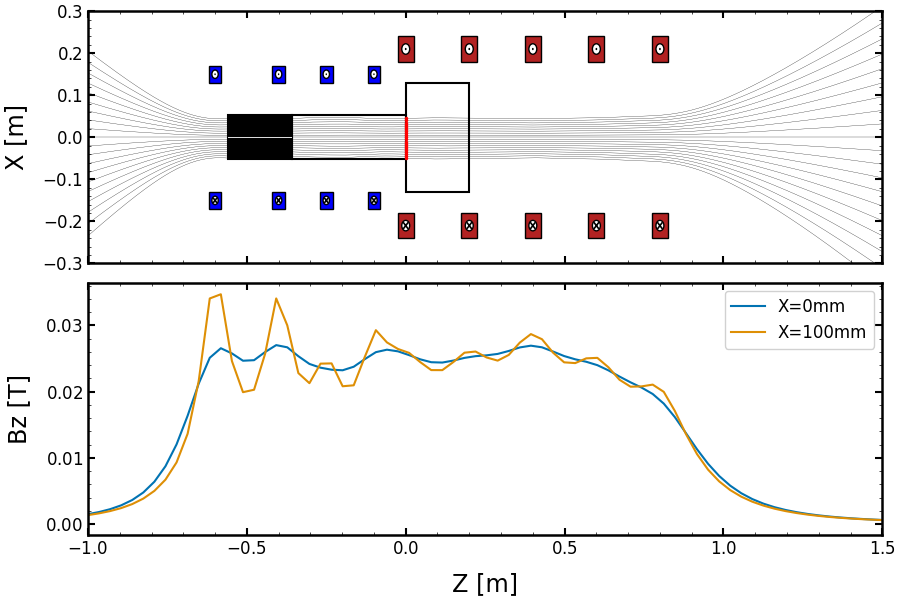

In [21]:
spxmag = magcalc.MagSPHINX("./SPHINX_arcsource_default.toml")
# ========================================
# coil current setting
# ========================================
# spxmag.change_coil_gen_current(20000)
# spxmag.change_coil_test_current(500 * 32)


xz = [[x, 0] for x in np.arange(-50e-3, 50e-3, 5e-3)]  # initial x positions of field lines
x_list, z_list = spxmag.get_magnetic_field_lines(init_xz_pair_list=xz, bidirectional=True, min_field=1e-5)


fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
# magnetic field lines
for x, z in zip(x_list, z_list):
    axes[0].plot(z, x, color="black", lw=0.2)
for ix, iz in xz:
    axes[0].plot(iz, ix, "ro", markersize=1)
# magnetic field strength along z-axis
zz = np.linspace(-1.0, 2.45, 100)
Bz = spxmag.get_B(x=0, z=zz, y=0).Bz.data.squeeze()    #X=0mmでの磁場取得
Bzz = spxmag.get_B(x=0.1, z=zz, y=0).Bz.data.squeeze() #X=100mmでの磁場取得
axes[1].plot(zz, Bz, label="X=0mm")
axes[1].plot(zz, Bzz, label="X=100mm")

spxmag.plot_drawing(axes[0], module_num=1)
spxmag.plot_direction(axes[0])

axes[1].set_xlabel("Z [m]")
axes[0].set_ylabel("X [m]")
axes[0].set_xlim(-1.0, 1.5)
#axes[0].set_ylim(0, 0.3)
axes[0].set_ylim(-0.3, 0.3)
axes[1].set_ylabel("Bz [T]")
#axes[1].set_ylim(ymax=0.04)

axes[1].legend()


In [13]:
spxmag.show()

(-0.3, 0.3)

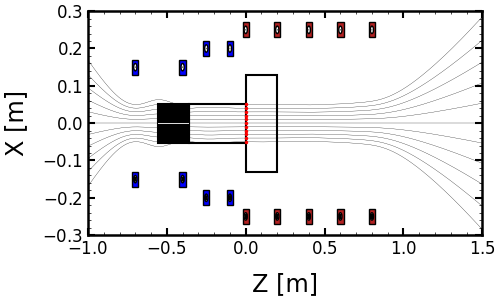

In [14]:
xz = [[x, 0] for x in np.arange(-50e-3, 60e-3, 10e-3)]  # initial x positions of field lines
# print(xz)
# spxmag.change_coil_gen_current(150 * 200)
# spxmag.change_coil_test_current(150*32)
x_list, z_list = spxmag.get_magnetic_field_lines(init_xz_pair_list=xz, bidirectional=True, min_field=1e-5)


fig, axes[0] = plt.subplots(figsize=(5, 3))

# magnetic field lines
for x, z in zip(x_list, z_list):
    axes[0].plot(z, x, color="black", lw=0.2)
for ix, iz in xz:
    axes[0].plot(iz, ix, "ro", markersize=1)

spxmag.plot_drawing(axes[0], module_num=1)
spxmag.plot_direction(axes[0])


axes[0].set_ylabel("X [m]")
axes[0].set_xlabel("Z [m]")
axes[0].set_xlim(-1.0, 1.5)
#axes[0].set_ylim(0, 0.3)
axes[0].set_ylim(-0.3, 0.3)

    